In [46]:
import matplotlib.pyplot as plt
import numpy as np

from challenge.dataset import Dataset
from challenge.visuals import plot_image_with_boxes
import cv2

In [ ]:
train_data = Dataset("../data/data_notebook.yaml", split="train")
val_data = Dataset("../data/data_notebook.yaml", split="val")


In [13]:
rng = np.random.default_rng(42)

In [10]:
names = {
    0: "Hammer",
    1: "Knife",
    2: "Gun",
    3: "Wrench",
    4: "HandCuffs",
    5: "Bullet",
}

# class_id -> list of dataset indices
class_to_indices = {k: [] for k in names}

for i in range(len(train_data)):
    targets = train_data[i]["targets"]  # shape (N, 5) typically
    if len(targets) == 0:
        continue

    labels = np.unique(targets[:, 0].astype(int))
    for c in labels:
        if c in class_to_indices:
            class_to_indices[c].append(i)

In [14]:
samples_per_class = 6

selected = {}
for c, idxs in class_to_indices.items():
    if len(idxs) < samples_per_class:
        print(f"Warning: class {names[c]} has only {len(idxs)} samples")
    selected[c] = rng.choice(
        idxs,
        size=min(samples_per_class, len(idxs)),
        replace=False,
    )

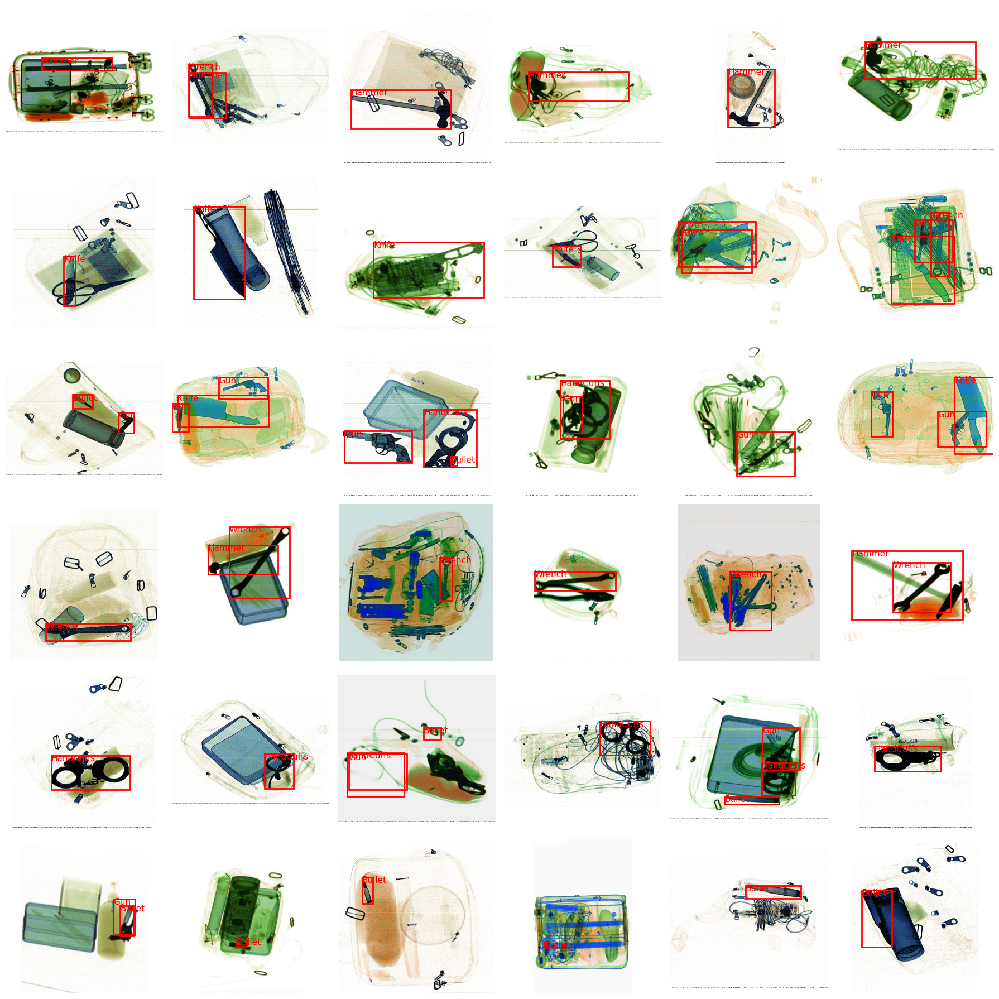

In [16]:
n_classes = len(names)
fig, axes = plt.subplots(
    n_classes,
    samples_per_class,
    figsize=(3 * samples_per_class, 3 * n_classes),
)

for row, (c, idxs) in enumerate(selected.items()):
    for col, idx in enumerate(idxs):
        ax = axes[row, col]
        plot_image_with_boxes(
            ax,
            train_data[idx]["image"],
            train_data[idx]["targets"],
            color="red",
        )
        ax.axis("off")

    axes[row, 0].set_ylabel(names[c], fontsize=12)

plt.tight_layout()

In [ ]:
hammer_data = Dataset(
    "../data/data_notebook.yaml", split="train", filter_classes=set({0})
)

In [ ]:
def extract_features_from_contour(contour, img_shape) -> dict:
    features = {}

    # Basic area and perimeter
    area = cv2.contourArea(contour)
    perimeter = cv2.arcLength(contour, True)

    if area == 0 or perimeter == 0:
        return None

    # Bounding box features
    x, y, w, h = cv2.boundingRect(contour)
    features["bbox_x"] = x
    features["bbox_y"] = y
    features["bbox_w"] = w
    features["bbox_h"] = h
    features["bbox_area"] = w * h

    # Aspect ratio from axis-aligned bbox
    features["bbox_aspect_ratio"] = max(w, h) / (min(w, h) + 1e-6)

    # Minimum area rectangle (rotation invariant)
    rect = cv2.minAreaRect(contour)
    (cx, cy), (width, height), angle = rect
    features["center_x"] = cx / img_shape[1]  # normalize
    features["center_y"] = cy / img_shape[0]
    features["obb_width"] = width
    features["obb_height"] = height
    features["obb_angle"] = angle
    features["obb_aspect_ratio"] = max(width, height) / (min(width, height) + 1e-6)

    # Area-based features
    features["area"] = area
    features["perimeter"] = perimeter
    features["extent"] = area / (w * h + 1e-6)

    # Solidity (convexity measure)
    hull = cv2.convexHull(contour)
    hull_area = cv2.contourArea(hull)
    features["solidity"] = area / (hull_area + 1e-6)
    features["hull_area"] = hull_area

    # Circularity
    features["circularity"] = 4 * np.pi * area / (perimeter**2 + 1e-6)

    # Hu Moments (7 rotation-invariant moments)
    moments = cv2.moments(contour)
    if moments["m00"] != 0:
        hu_moments = cv2.HuMoments(moments).flatten()
        # Use log scale for Hu moments (they can be very small)
        for i, hu in enumerate(hu_moments):
            features[f"hu_{i}"] = -np.sign(hu) * np.log10(np.abs(hu) + 1e-10)
    else:
        for i in range(7):
            features[f"hu_{i}"] = 0

    # Eccentricity from fitted ellipse
    if len(contour) >= 5:  # need at least 5 points to fit ellipse
        try:
            ellipse = cv2.fitEllipse(contour)
            (ex, ey), (ma, MA), angle_e = ellipse
            features["ellipse_major_axis"] = MA
            features["ellipse_minor_axis"] = ma
            features["eccentricity"] = (
                np.sqrt(1 - (ma / (MA + 1e-6)) ** 2) if MA > 0 else 0
            )
        except:
            features["ellipse_major_axis"] = 0
            features["ellipse_minor_axis"] = 0
            features["eccentricity"] = 0
    else:
        features["ellipse_major_axis"] = 0
        features["ellipse_minor_axis"] = 0
        features["eccentricity"] = 0

    # Convexity defects (measure of "dents" in the shape)
    hull_indices = cv2.convexHull(contour, returnPoints=False)
    if hull_indices is not None and len(hull_indices) > 3:
        try:
            defects = cv2.convexityDefects(contour, hull_indices)
            if defects is not None:
                # Average defect depth
                defect_depths = defects[:, 0, 3] / 256.0  # convert to pixels
                features["avg_defect_depth"] = np.mean(defect_depths)
                features["max_defect_depth"] = np.max(defect_depths)
                features["num_defects"] = len(defects)
            else:
                features["avg_defect_depth"] = 0
                features["max_defect_depth"] = 0
                features["num_defects"] = 0
        except:
            features["avg_defect_depth"] = 0
            features["max_defect_depth"] = 0
            features["num_defects"] = 0
    else:
        features["avg_defect_depth"] = 0
        features["max_defect_depth"] = 0
        features["num_defects"] = 0

    return features


In [ ]:
def segment_and_extract_features(
    img: np.ndarray,
    fg_percentile: float = 92,
    close_kernel: int = 9,
    open_kernel: int = 3,
    hole_kernel: int = 5,
    min_area_frac: float = 0.01,
    min_length_frac: float = 0.18,  # ← length filtering
    min_elongation: float = 3.0,  # ← elongation filtering
) -> tuple[np.ndarray, list[dict]]:
    H, W = img.shape[:2]
    min_area = int(min_area_frac * H * W)
    min_length = min_length_frac * max(H, W)

    # --- Foreground extraction ---
    white = np.array([255, 255, 255])
    dist = np.linalg.norm(img.astype(np.int16) - white, axis=2)

    # --- NEW ---
    fg_mask = hysteresis_foreground(
        img,
        low_p=fg_percentile - 7,  # e.g. 85 if fg_percentile=92
        high_p=fg_percentile,
    )
    # --- Reconnect thin structures ---
    fg_mask = cv2.morphologyEx(
        fg_mask,
        cv2.MORPH_CLOSE,
        cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (close_kernel, close_kernel)),
    )

    # --- Light opening ---
    fg_mask = cv2.morphologyEx(
        fg_mask,
        cv2.MORPH_OPEN,
        cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (open_kernel, open_kernel)),
    )

    # --- Connected components ---
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
        fg_mask, connectivity=8
    )

    clean_mask = np.zeros_like(fg_mask)
    for i in range(1, num_labels):
        if stats[i, cv2.CC_STAT_AREA] >= min_area:
            clean_mask[labels == i] = 1

    # --- Gentle hole closing ---
    filled_mask = cv2.morphologyEx(
        clean_mask,
        cv2.MORPH_CLOSE,
        cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (hole_kernel, hole_kernel)),
    )

    # --- Contours ---
    contours, _ = cv2.findContours(
        filled_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    all_features = []
    for contour in contours:
        area = cv2.contourArea(contour)
        if area < min_area:
            continue

        # --- LENGTH + ELONGATION FILTER (HERE, AS REQUESTED) ---
        rect = cv2.minAreaRect(contour)
        w, h = rect[1]

        if w == 0 or h == 0:
            continue

        length = max(w, h)
        elongation = length / min(w, h)

        if length < min_length:
            continue

        if elongation < min_elongation:
            continue

        # --- Feature extraction ---
        features = extract_features_from_contour(contour, img.shape[:2])
        if features is not None:
            features["contour"] = contour
            features["length"] = length
            features["elongation"] = elongation
            all_features.append(features)

    return filled_mask, all_features

In [ ]:
def hysteresis_foreground(img, low_p=85, high_p=95):
    white = np.array([255, 255, 255])
    dist = np.linalg.norm(img.astype(np.int16) - white, axis=2)

    thr_low = np.percentile(dist, low_p)
    thr_high = np.percentile(dist, high_p)

    weak = dist > thr_low
    strong = dist > thr_high

    # Keep weak pixels only if connected to strong ones
    num, labels = cv2.connectedComponents(weak.astype(np.uint8), connectivity=8)

    out = np.zeros_like(weak, dtype=np.uint8)
    for i in range(1, num):
        if np.any(strong[labels == i]):
            out[labels == i] = 1

    return out

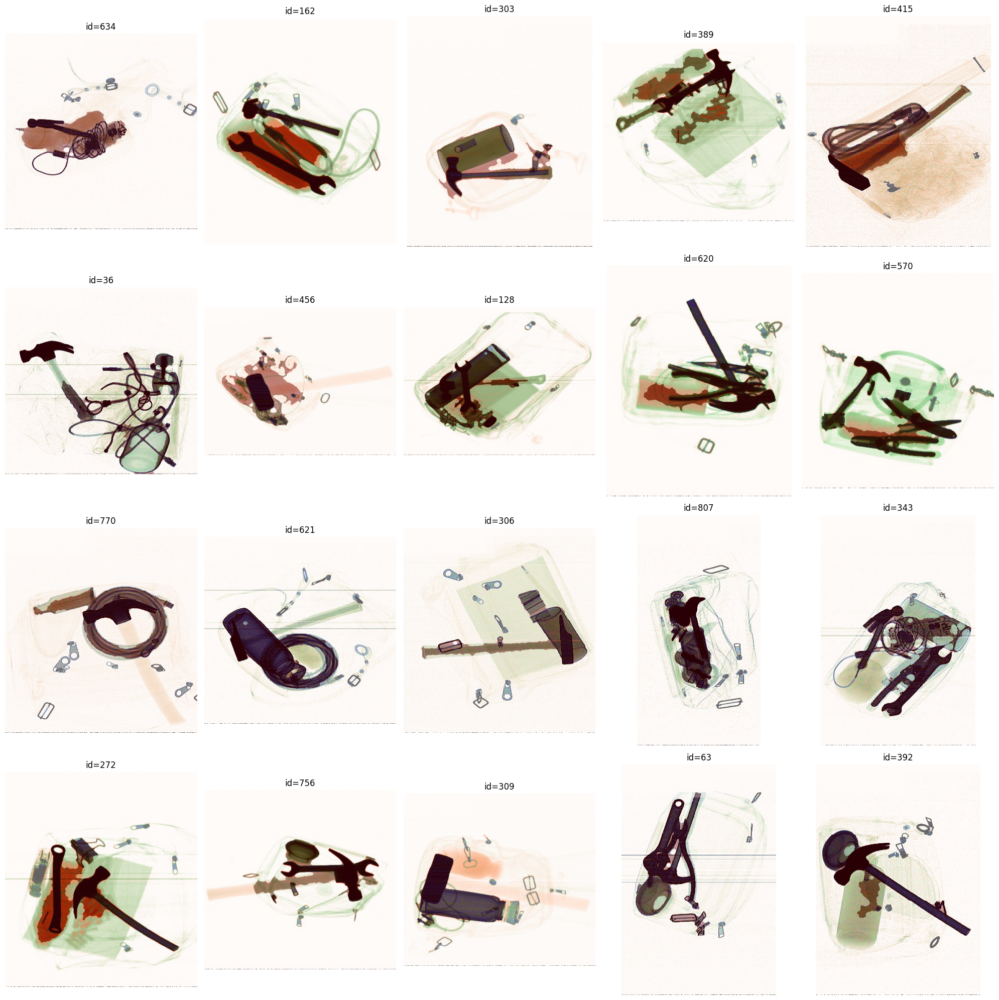

In [317]:
idx = rng.integers(0, len(hammer_data), 20)

fig, ax = plt.subplots(4, 5, figsize=(20, 20))
ax = ax.flatten()

for i, id in enumerate(idx):
    img = hammer_data[id]["image"]
    mask, _ = segment_and_extract_features(img, fg_percentile=97)

    ax[i].imshow(img)
    ax[i].imshow(mask, alpha=0.4, cmap="Reds")
    ax[i].set_title(f"id={id}")
    ax[i].axis("off")

plt.tight_layout()
plt.show()

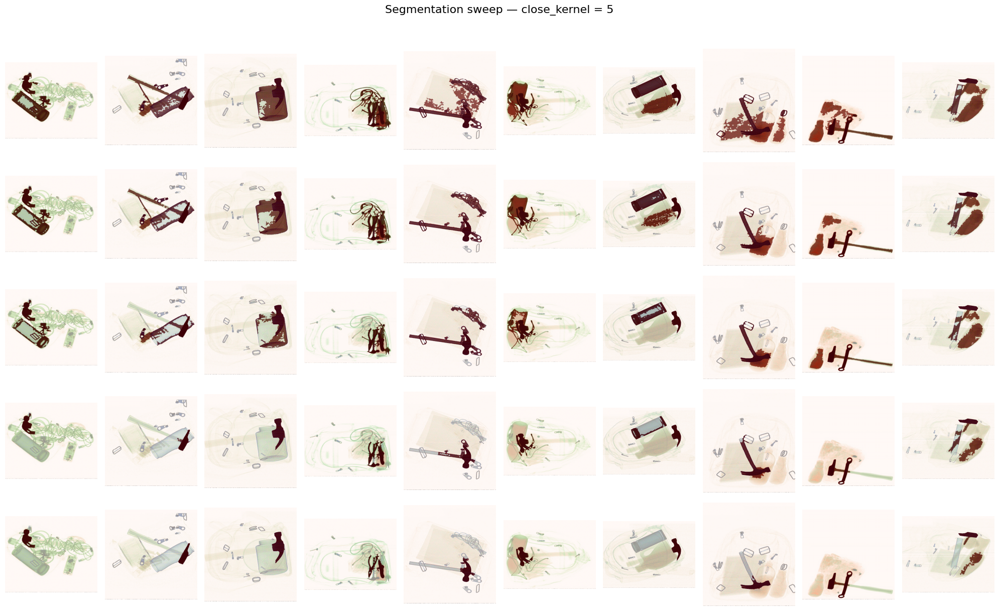

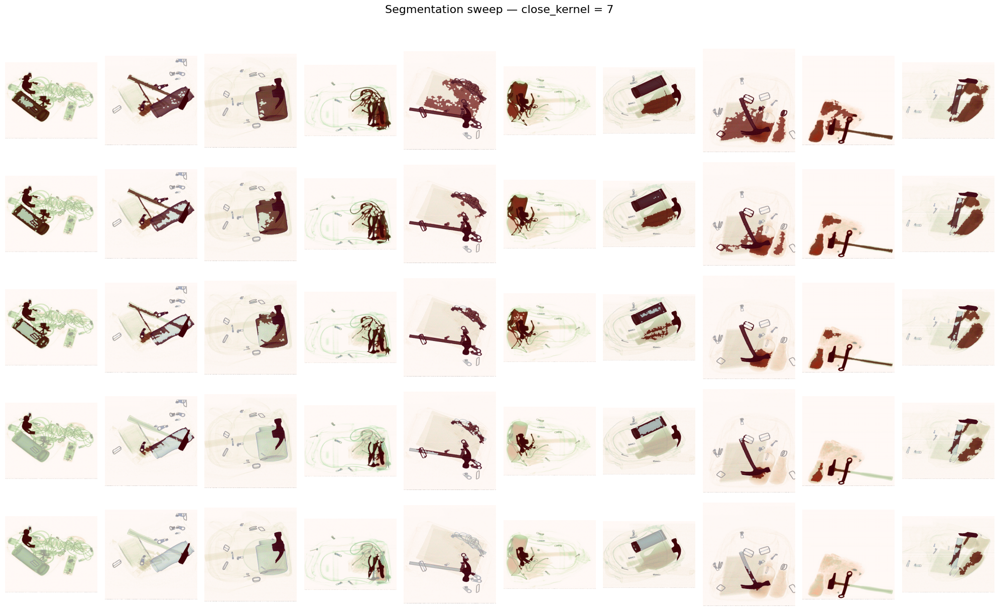

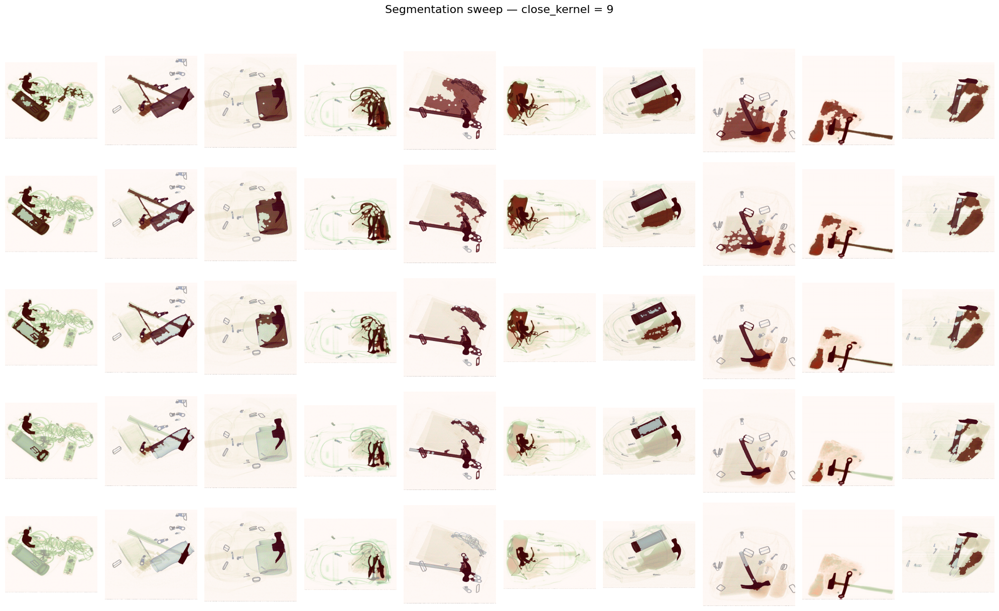

In [ ]:
fg_percentiles = [90, 92, 94, 96, 97]
close_kernels = [5, 7, 9]


def plot_row(ax_row, idx, fg_percentile, close_kernel):
    for j, id in enumerate(idx):
        img = hammer_data[id]["image"]
        mask, _ = segment_and_extract_features(
            img,
            fg_percentile=fg_percentile,
            close_kernel=close_kernel,
        )

        ax_row[j].imshow(img)
        ax_row[j].imshow(mask, alpha=0.6, cmap="Reds")
        ax_row[j].axis("off")

    ax_row[0].set_ylabel(
        f"fg={fg_percentile}\nk={close_kernel}",
        fontsize=12,
        rotation=0,
        labelpad=40,
        va="center",
    )


rng = np.random.default_rng(42)
idx = rng.integers(0, len(hammer_data), 10)

fg_percentiles = [90, 92, 94, 96, 97]
close_kernels = [5, 7, 9]

for k in close_kernels:
    fig, ax = plt.subplots(
        len(fg_percentiles),
        len(idx),
        figsize=(2 * len(idx), 2.5 * len(fg_percentiles)),
    )

    for i, fg_p in enumerate(fg_percentiles):
        plot_row(ax[i], idx, fg_p, k)

    plt.suptitle(f"Segmentation sweep — close_kernel = {k}", fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

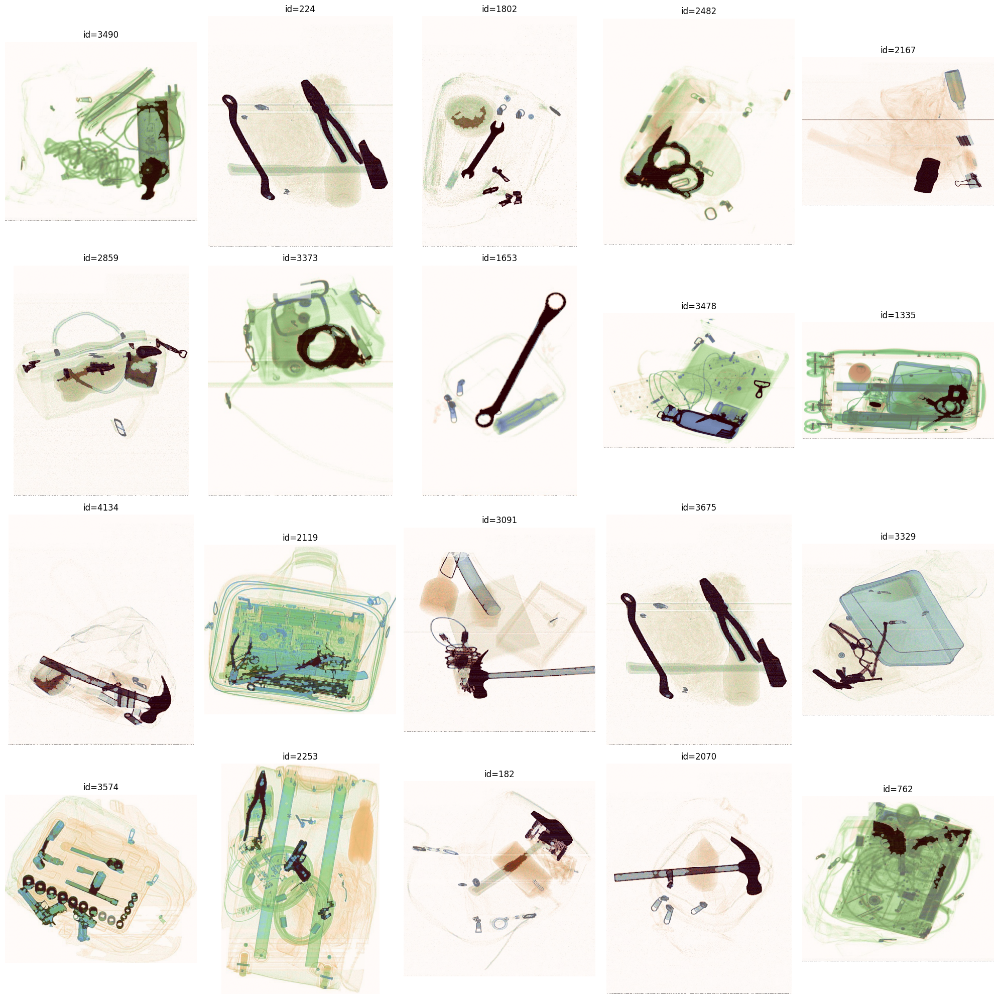

In [298]:
idx = rng.integers(0, len(train_data), 20)

fig, ax = plt.subplots(4, 5, figsize=(20, 20))
ax = ax.flatten()

for i, id in enumerate(idx):
    img = train_data[id]["image"]
    mask, _ = segment_and_extract_features(img, fg_percentile=97)

    ax[i].imshow(img)
    ax[i].imshow(mask, alpha=0.4, cmap="Reds")
    ax[i].set_title(f"id={id}")
    ax[i].axis("off")

plt.tight_layout()
plt.show()

In [267]:
filled_mask, features_list = segment_and_extract_features(img)

In [271]:
len(features_list)

2

In [ ]:
white = np.array([255, 255, 255])
dist = np.linalg.norm(img - white, axis=2)

In [ ]:
thr = np.percentile(dist, 97)
fg_mask = dist > thr

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
fg_mask = cv2.morphologyEx(fg_mask.astype(np.uint8), cv2.MORPH_CLOSE, kernel)

num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(fg_mask, connectivity=8)

min_area = 300  # tune later
clean_mask = np.zeros_like(fg_mask)

for i in range(1, num_labels):
    if stats[i, cv2.CC_STAT_AREA] >= min_area:
        clean_mask[labels == i] = 1

h, w = clean_mask.shape
flood = clean_mask.copy()

mask = np.zeros((h + 2, w + 2), np.uint8)
cv2.floodFill(flood, mask, seedPoint=(0, 0), newVal=1)

holes = 1 - flood
filled_mask = clean_mask | holes

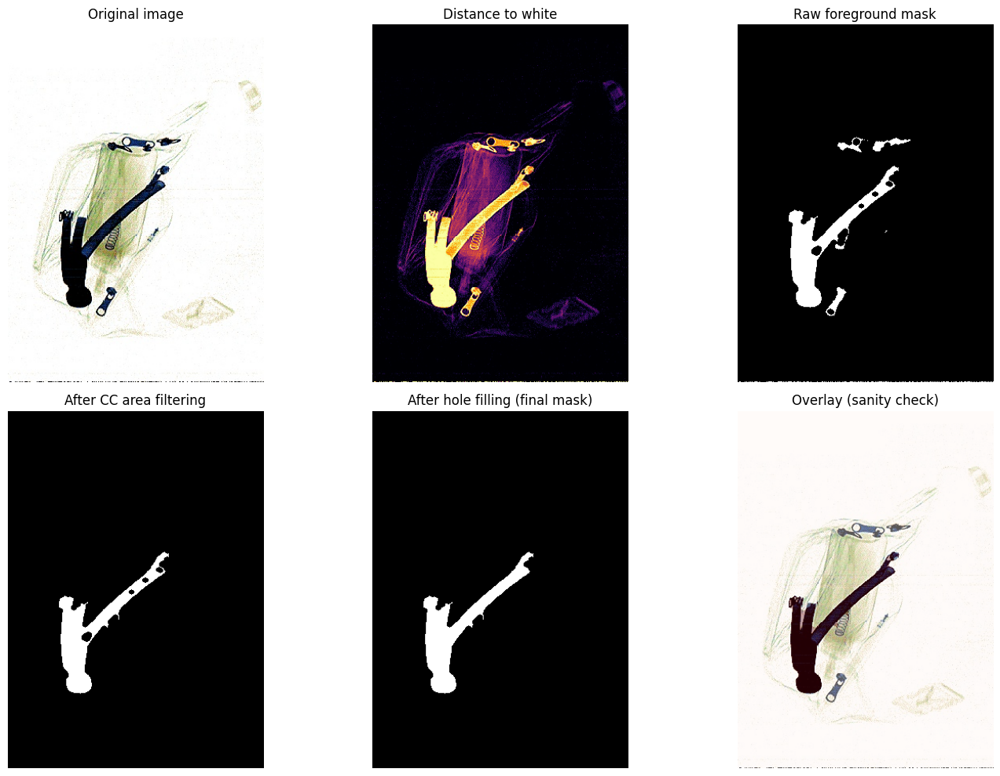

In [94]:
fig, ax = plt.subplots(2, 3, figsize=(15, 10))
ax = ax.flatten()

# 1) Original image
ax[0].imshow(img)
ax[0].set_title("Original image")
ax[0].axis("off")

# 2) Distance to white
ax[1].imshow(dist, cmap="inferno")
ax[1].set_title("Distance to white")
ax[1].axis("off")

# 3) Raw foreground mask (after threshold)
ax[2].imshow(fg_mask, cmap="gray")
ax[2].set_title("Raw foreground mask")
ax[2].axis("off")

# 4) Clean mask (after CC filtering)
ax[3].imshow(clean_mask, cmap="gray")
ax[3].set_title("After CC area filtering")
ax[3].axis("off")

# 5) Filled mask (final binary topology)
ax[4].imshow(filled_mask, cmap="gray")
ax[4].set_title("After hole filling (final mask)")
ax[4].axis("off")

# 6) Overlay (this is the most important panel)
ax[5].imshow(img)
ax[5].imshow(filled_mask, alpha=0.35, cmap="Reds")
ax[5].set_title("Overlay (sanity check)")
ax[5].axis("off")

plt.tight_layout()
plt.show()